---
title: ""
lang: uk
format:
  typst:
    mainfont: "Times New Roman"
    fontsize: 14pt
    margin: { x: 2.5cm, y: 2.5cm }
  docx: default
  pdf:
    pdf-engine: lualatex
    mainfont: "Times New Roman"
---

```{=typst}
// Configure the page.
#set page(
  paper: "a4",
  // The margins depend on the paper size.
  margin: (x: 2cm, y: 1.5cm),
  numbering:  (current, total) => if current > 1 { current }, number-align: right, 
)

// Configure styling
#set par(
  leading: 0.8em,
  spacing: 1em,
  justify: true,
)
#show table: set text(size: 9pt)

#align(top + center)[
  Міністерство освіти і науки України \
  Національний університет «Львівська політехніка» \
  Кафедра систем штучного інтелекту \
  \
  #image("logo.png", width: 6cm)
  \
  #set par(spacing: 0.4em)
  #text(size: 24pt, weight: "bold")[Звіт]
  #set par(spacing: 0.8em)

  *про виконання лабораторної роботи № 10* \
  _з дисципліни:_ «Обробка мови методами штучного інтелекту»
]

#align(bottom + right)[
  Виконав: \
  студент групи ШІ-42 \
  Горишевський Олексій Олександрович
]

#pagebreak()
```

# Модель рішень у стилі Jev

Модель отримує текст і кілька питань до нього та повертає ймовірності дозволених відповідей.
Текст вона не генерує, тому формат відповіді завжди правильний, а кількість згенерованих токенів
дорівнює нулю.

Типи питань:

- **noul** - так чи ні, відповідь - ймовірність «так»;
- **choice** - вибір одного варіанта з кількох;
- **score** - оцінка за шкалою 0..K−1, відповідь - очікуване значення.

In [1]:
%cd lab-10
!uv sync -q

/home/rojikaru/Projects/labs/grade-4.1/llm/lab-10


In [2]:
import json
from pathlib import Path
from IPython.display import Image, display

## Дані

Для навчання взято публічні набори й перетворено їх на питання потрібних типів:

- BoolQ та MNLI - noul;
- AG News та RACE - choice;
- Yelp - score з п'ятьма рівнями.

З кожного набору - до 8000 прикладів, 5% з них відкладено на валідацію.

Для тестування - набори, яких модель не бачила під час навчання:

- BoolQ (validation) та Amazon Polarity - noul;
- Banking77 - choice з новими мітками;
- Belebele та SIB-200 українською - choice;
- Yelp (test) - score.

In [3]:
!uv run python -m decide.data --stats

source             type    split    rows  majority


boolq              noul    train    7600 
mnli               noul    train    7600 
ag_news            choice  train    7600 
race               choice  train    7600 
yelp               score   train    7600 
boolq              noul    val       400 
mnli               noul    val       400 
ag_news            choice  val       400 
race               choice  val       400 
yelp               score   val       400 
boolq_val          noul    test     2000     0.626
amazon_polarity    noul    test     2000     0.511
banking77          choice  test     2000     0.213
belebele_uk        choice  test      900     0.279
sib200_uk          choice  test      204     0.250
yelp_test          score   test     2000     0.221


## Приклад запиту

Кожне питання має тип, інструкцію та, для choice і score, варіанти відповіді.

In [4]:
request = json.loads(Path("canonical_request.json").read_text())
print(json.dumps(request, ensure_ascii=False, indent=2))

{
  "model": "jev-latest",
  "state": "Вітаю! З мене двічі списали оплату за місячну підписку. Поверніть, будь ласка, зайве. Акаунт працює нормально, але я вже третій день не можу до вас додзвонитися.",
  "questions": {
    "department": {
      "type": "choice",
      "instructions": "Яка команда має обробити цей запит?",
      "criteria": {
        "billing": "Рахунки, оплати, повернення коштів",
        "technical": "Баги, збої, помилки системи",
        "sales": "Ціни, нові контракти",
        "other": "Усе інше"
      }
    },
    "frustration": {
      "type": "score",
      "instructions": "Наскільки клієнт роздратований?",
      "criteria": [
        "Спокійний, нейтральний тон",
        "Помірне невдоволення",
        "Сильне роздратування або погрози піти"
      ]
    },
    "wants_refund": {
      "type": "noul",
      "instructions": "Клієнт явно просить повернути кошти?"
    }
  }
}


## Модель

- Енкодер - `jhu-clsp/mmBERT-small` (140M параметрів, багатомовний).
- Вхід: `[CLS] текст [SEP] питання [SEP] варіант 1 [SEP] варіант 2 [SEP] …`, до 512 токенів.
  Якщо задовго - обрізаємо кінець тексту.
- Для noul - лінійний шар на векторі `[CLS]` і сигмоїда.
- Для choice і score - середнє токенів кожного варіанта, лінійний шар і softmax по варіантах.
- Після навчання для кожного типу підбираємо температуру на валідації.
- Впевненість: `(p_max − 1/K) / (1 − 1/K)`.

## Тренування

AdamW, lr 3e-5, батч 16, 2 епохи, bf16. В одному батчі - питання одного типу, а порядок
варіантів щоразу перемішується. Зберігаємо епоху з найменшою втратою на валідації.

In [5]:
if not Path("checkpoints/best.pt").exists():
    !uv run python -m decide.train --epochs 2 --batch-size 16 --out checkpoints/best.pt --tag main
metrics = json.loads(Path("reports/metrics.json").read_text())
train = metrics["train_main"]
for row in train["history"]:
    print(f"епоха {row['epoch']}: train loss {row['train_loss']:.4f}, val loss {row['val_loss']:.4f}")
print(f"час: {train['wall_time_s'] / 60:.1f} хв, пам'ять GPU: {train['peak_vram_gb']:.2f} ГБ")

епоха 1: train loss 0.7685, val loss 0.6382
епоха 2: train loss 0.4610, val loss 0.5958
час: 24.3 хв, пам'ять GPU: 5.02 ГБ


## Оцінка

Порівнюємо з мажоритарним класом і з zero-shot класифікацією
`MoritzLaurer/mDeBERTa-v3-base-mnli-xnli`. Калібрування міряємо через ECE (15 бінів) до і
після температури.

In [6]:
if "results" not in metrics:
    !uv run python -m decide.evaluate --checkpoint checkpoints/best.pt --baselines --latency
    metrics = json.loads(Path("reports/metrics.json").read_text())
results = metrics["results"]
for name, r in results["tests"].items():
    line = f"{name}: точність {r['accuracy']:.3f}, мажоритарний {r['majority']:.3f}"
    if "zero_shot" in r:
        line += f", zero-shot {r['zero_shot']:.3f}"
    if "f1" in r:
        line += f", F1 {r['f1']:.3f}"
    print(line + f", ECE {r['ece_before']:.3f} -> {r['ece_after']:.3f}")
print("температури:", results["temperature"])

boolq_val: точність 0.776, мажоритарний 0.626, F1 0.828, ECE 0.053 -> 0.018
amazon_polarity: точність 0.911, мажоритарний 0.511, F1 0.906, ECE 0.051 -> 0.122
banking77: точність 0.671, мажоритарний 0.213, zero-shot 0.703, ECE 0.140 -> 0.235
belebele_uk: точність 0.403, мажоритарний 0.279, zero-shot 0.343, ECE 0.187 -> 0.105
sib200_uk: точність 0.711, мажоритарний 0.250, zero-shot 0.466, ECE 0.092 -> 0.200
yelp_test: точність 0.609, мажоритарний 0.221, ECE 0.067 -> 0.022
температури: {'noul': 1.45, 'choice': 1.45, 'score': 1.25}


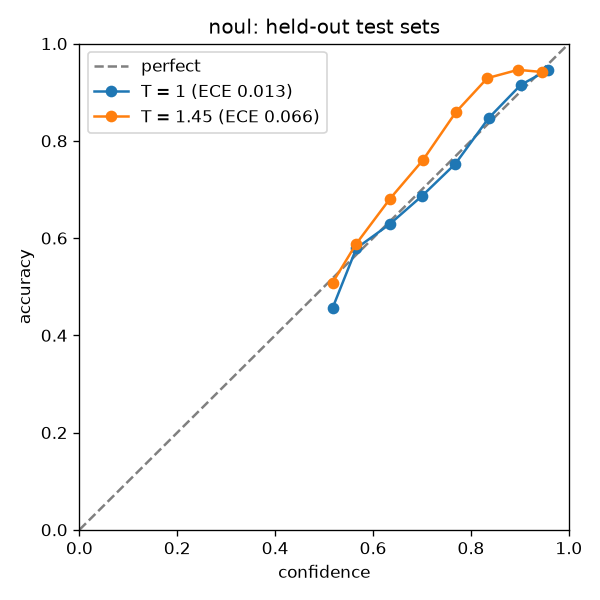

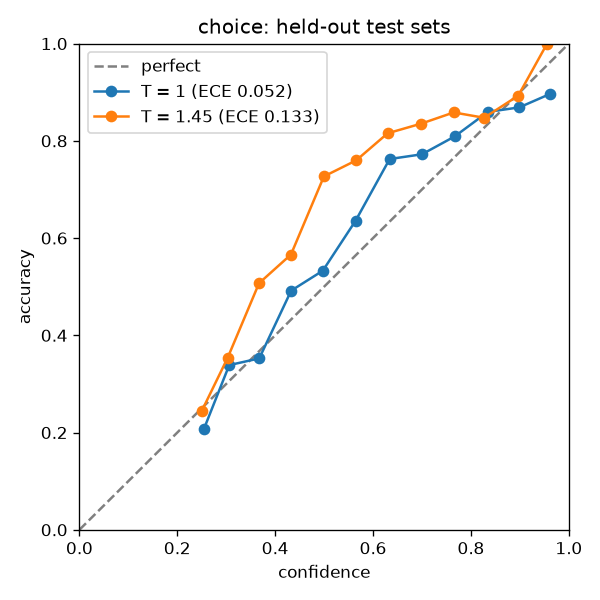

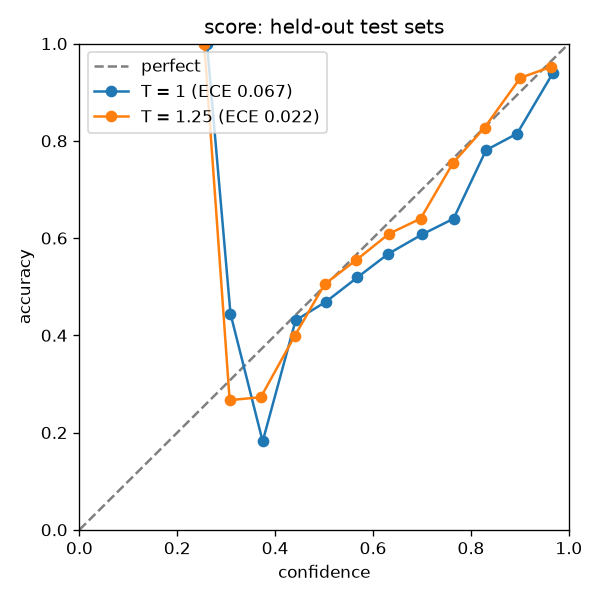

In [7]:
for kind in ("noul", "choice", "score"):
    display(Image(filename=f"reports/reliability_{kind}.png", width=380))

## Більша модель

Для порівняння той самий процес з `jhu-clsp/mmBERT-base` (307M). У 8 ГБ вона вмістилась лише з
батчем 4 і накопиченням градієнта на 4 кроки та замороженими ембедингами.

In [8]:
base = metrics["results_base"]
for name, r in base["tests"].items():
    print(f"{name}: small {results['tests'][name]['accuracy']:.3f}, base {r['accuracy']:.3f}")

boolq_val: small 0.776, base 0.787
amazon_polarity: small 0.911, base 0.929
banking77: small 0.671, base 0.533
belebele_uk: small 0.403, base 0.559
sib200_uk: small 0.711, base 0.760
yelp_test: small 0.609, base 0.638


## Сервіс

Запускаємо API і надсилаємо приклад запиту.

In [9]:
import os, subprocess, time, urllib.request

server = subprocess.Popen(
    ["uv", "run", "uvicorn", "decide.service:app", "--port", "8765"],
    env={**os.environ, "DECIDE_CHECKPOINT": "checkpoints/best.pt"},
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)
try:
    for _ in range(120):
        try:
            urllib.request.urlopen("http://127.0.0.1:8765/health")
            break
        except OSError:
            time.sleep(1)
    http_request = urllib.request.Request(
        "http://127.0.0.1:8765/v1/systemone",
        data=json.dumps(request).encode(),
        headers={"content-type": "application/json"},
    )
    response = json.loads(urllib.request.urlopen(http_request).read())
finally:
    server.terminate()
print(json.dumps(response, ensure_ascii=False, indent=2))

{
  "model": "decide-mmbert-small-283ba19",
  "answers": {
    "department": {
      "type": "choice",
      "choice": "billing",
      "probabilities": {
        "billing": 0.351,
        "technical": 0.3383,
        "other": 0.2009,
        "sales": 0.1099
      },
      "confidence": 0.1346
    },
    "frustration": {
      "type": "score",
      "score": 1.4036,
      "confidence": 0.2874,
      "probabilities": {
        "0": 0.1213,
        "1": 0.3538,
        "2": 0.5249
      },
      "legend": {
        "0": "Спокійний, нейтральний тон",
        "1": "Помірне невдоволення",
        "2": "Сильне роздратування або погрози піти"
      }
    },
    "wants_refund": {
      "type": "noul",
      "noul": 0.6599
    }
  },
  "usage": {
    "input_tokens": 289,
    "output_tokens": 0
  }
}


In [10]:
service = metrics["service"]
print(f"GPU: {service['latency_ms_cuda']:.1f} мс на запит, CPU: {service['latency_ms_cpu']:.1f} мс на запит")

GPU: 11.8 мс на запит, CPU: 151.9 мс на запит


## Тести

In [11]:
!uv run pytest -q
!uv run python check_budget.py

.

.....

....

.....

...                                                       [100%]
18 passed in 1.15s


file                                              SLOC  max CC  max cog
src/decide/__init__.py                               0       0        0
src/decide/calibrate.py                             49       4        2
src/decide/data.py                                 128       4        6
src/decide/encode.py                                47       5        3
src/decide/evaluate.py                             138       8        5
src/decide/model.py                                 63       4        1
src/decide/schema.py                                41       0        0
src/decide/service.py                               81       7        2
src/decide/train.py                                151       6        6
src total SLOC: 698/700
tests total SLOC: 197/300


BUDGET OK


### Висновки

1. Модель перевищує мажоритарний клас на всіх шести тестових наборах: BoolQ - 0.776 проти 0.626, Yelp - 0.609 проти 0.221. На Amazon Polarity з питанням, якого не було під час навчання, точність 0.911 проти 0.511.
2. Порівняно з zero-shot mDeBERTa модель краща на українських наборах (Belebele - 0.403 проти 0.343, SIB-200 - 0.711 проти 0.466), але гірша на Banking77 (0.671 проти 0.703), де мітки нові. Українське читання лишається слабким: 0.403 лише трохи вище за мажоритарні 0.279.
3. Без температури калібрування вже непогане: ECE на всіх тестах разом 0.013 для noul, 0.052 для choice і 0.067 для score. Температура, підібрана на валідації (1.45, 1.45, 1.25), покращила BoolQ і Yelp (0.053 → 0.018 і 0.067 → 0.022), але погіршила набори з інших доменів (Amazon 0.051 → 0.122, Banking77 0.140 → 0.235): на незнайомих даних модель і так недостатньо впевнена.
4. mmBERT-base точніша на чотирьох наборах із шести (Belebele 0.559, Amazon 0.929), але гірша на Banking77 (0.533). У 8 ГБ вона вмістилась лише з батчем 4 і замороженими ембедингами, тоді як small з батчем 16 тренувалась 24 хв і зайняла 5 ГБ.
5. Відповідь отримуємо без генерації: 0 вихідних токенів, 12 мс на запит на GPU і 152 мс на CPU, а формат завжди правильний. На прикладі зі звернення про подвійне списання модель обирає billing, але майже навмання (0.35 проти 0.34 для technical): українських звернень до підтримки в навчальних даних не було.